# #30DayMapChallenge — Day 10: neighbours, near and far

This notebook builds the final submission from start to end. Every small area in the UK (LSOAs in England and Wales, Data Zones in Scotland, Super Data Zones in Northern Ireland) has an AlphaEarth embedding for 2024: 64 numbers summarising a year of satellite observations. We compare every pair of neighbouring areas and turn three of them into Polaroid cards:

1. **The most different neighbours** in the UK.
2. **The most similar neighbours.**
3. **The most similar urban neighbours.**

The exploration behind these choices lives in `gdsl30dmc.ipynb` and `gdsl30dmc_clusters.ipynb`; this notebook depends only on the shared module `gdsl30dmc_tools.py` (data loading, contiguity and the Polaroid card template).

## Setup

Libraries for the whole pipeline. The shared module also registers the card fonts: Figtree for the caption and Special Elite, a typewriter face, for the haiku.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import gdsl30dmc_tools as tools

## Areas and their neighbours

We read the 2024 areas with their mean embeddings and connect every pair of areas whose polygons touch or overlap (fuzzy contiguity: queen contiguity plus the England–Scotland border, where the two nations' polygons overlap). Twelve island areas have no neighbours, so we drop them.

In [2]:
%%time
YEAR = 2024
areas = tools.load_areas(YEAR)
g = tools.contiguity(areas)
areas, g = tools.drop_isolates(areas, g)
print(f"{len(areas):,} areas | {g.n_edges // 2:,} neighbouring pairs")

46,832 areas | 136,233 neighbouring pairs
CPU times: user 5.64 s, sys: 173 ms, total: 5.81 s
Wall time: 5.83 s


## How different is each pair of neighbours?

For every neighbouring pair we compute the cosine distance between their embeddings: 0 means the two areas look the same to the model, and larger values mean more different. We compute it from scratch here (`cache=None`) rather than reading the copy cached by the exploration notebooks. Each pair appears once, with its two codes in alphabetical order.

In [3]:
dist = tools.pair_distances(areas, g, cache=None)
km2 = areas.area / 1e6
pairs = dist.reset_index().assign(km2_a=lambda d: km2[d.a].to_numpy(), km2_b=lambda d: km2[d.b].to_numpy())
pairs.dist.describe().round(4)

count    136233.0000
mean          0.0537
std           0.0583
min           0.0004
25%           0.0156
50%           0.0321
75%           0.0681
max           0.5382
Name: dist, dtype: float64

## Picking the three pairs

- **Most different:** the pair with the largest distance.
- **Most similar:** the pair with the smallest distance.
- **Most similar urban:** the smallest distance among pairs where both areas cover between 0.05 and 1 km². Areas are drawn to hold similar numbers of people, so small areas are urban. The lower bound leaves out tiny areas, whose average embedding rests on only a few hundred 10 m pixels and is less reliable.

On each card, the larger of the two areas is outlined in orange and the other in green.

In [4]:
URBAN_KM2 = (0.05, 1.0)
urban = pairs.km2_a.between(*URBAN_KM2) & pairs.km2_b.between(*URBAN_KM2)

picks = pd.DataFrame({
    "most_different": pairs.loc[pairs.dist.idxmax()],
    "most_similar": pairs.loc[pairs.dist.idxmin()],
    "most_similar_urban": pairs[urban].loc[pairs[urban].dist.idxmin()],
}).T
swap = picks.km2_b > picks.km2_a  # larger area first, so it is drawn in orange
picks.loc[swap, ["a", "b", "km2_a", "km2_b"]] = picks.loc[swap, ["b", "a", "km2_b", "km2_a"]].to_numpy()
picks["rank_different"] = [int((dist > d).sum()) + 1 for d in picks.dist]
picks["rank_similar"] = [int((dist < d).sum()) + 1 for d in picks.dist]
picks

,a,b,dist,km2_a,km2_b,rank_different,rank_similar
most_different,E01030745,E01030710,0.538219,2.093331,0.248516,1,136233
most_similar,N20000689,N20000681,0.000446,15.951039,13.802783,136233,1
most_similar_urban,E01003685,E01003730,0.00061,0.113929,0.0894,136229,5


## Captions

Each card carries a place name and a haiku in place of statistics. Place names were checked by reverse-geocoding each area's centre with OpenStreetMap (Nominatim):

- `E01030745` contains Staines Reservoirs, and `E01030710` is the housing of neighbouring Stanwell (Spelthorne, Surrey).
- The Armagh pair lies between Richhill and Hamiltonsbawn.
- The Ilford pair lies in Loxford and Seven Kings, London Borough of Redbridge (IG1).

The `expect` codes guard the captions: if the data or the rules ever change and a different pair is picked, the notebook stops instead of printing the wrong poem on a new picture.


In [5]:
N = len(dist)
CAPTIONS = {
    "most_different": dict(
        expect={"E01030745", "E01030710"}, place="Staines Reservoirs, Surrey",
        rank=lambda r: f"#1 most different of {N:,}",
        haiku="Still black reservoir —\nthe next street hangs out washing.\nNothing more apart."),
    "most_similar": dict(
        expect={"N20000681", "N20000689"}, place="Farmland, County Armagh",
        rank=lambda r: f"#1 most similar of {N:,}",
        haiku="Green field, hedge, green field.\nA map line says they are two;\nthe land knows just one."),
    "most_similar_urban": dict(
        expect={"E01003685", "E01003730"}, place="Ilford, east London",
        rank=lambda r: f"most similar urban pair (#{r.rank_similar} of {N:,})",
        haiku="Same bay window, same\nchimney pots, same Tuesday bins.\nTwo codes, one long street."),
}
for kind, r in picks.iterrows():
    assert {r.a, r.b} == CAPTIONS[kind]["expect"], f"{kind}: picked {r.a}–{r.b}, captions were written for another pair"


## The cards

Each card is a Polaroid: Esri satellite imagery washed out except over the two areas, the pair's codes as the title, the place, distance and rank underneath, the haiku in a typewriter face, and a UK locator. Cards are saved at 200 dpi to `figures/submission/`.

figures/submission/1_most_different.png


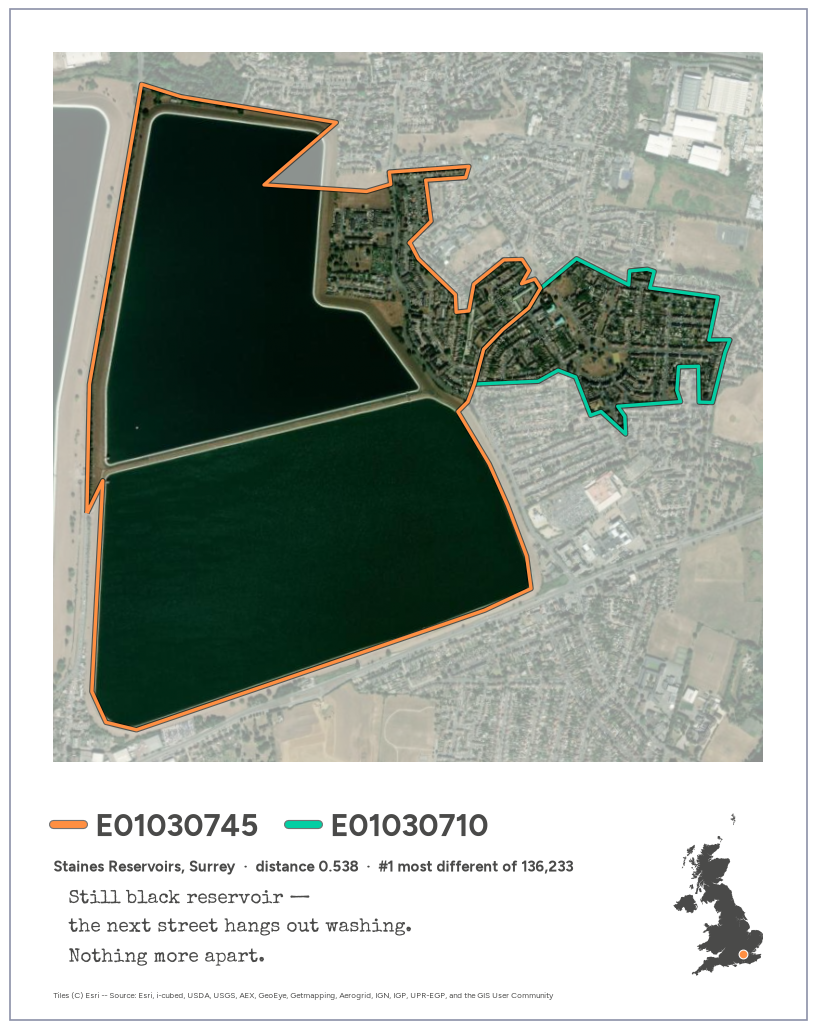

figures/submission/2_most_similar.png


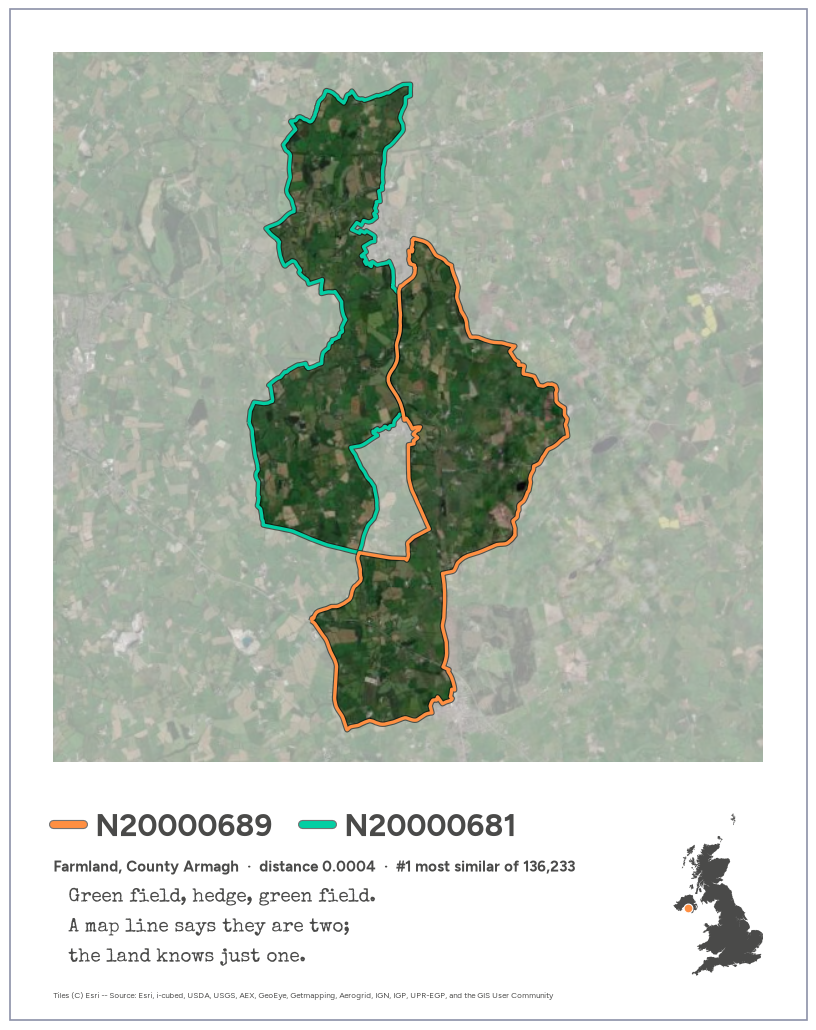

figures/submission/3_most_similar_urban.png


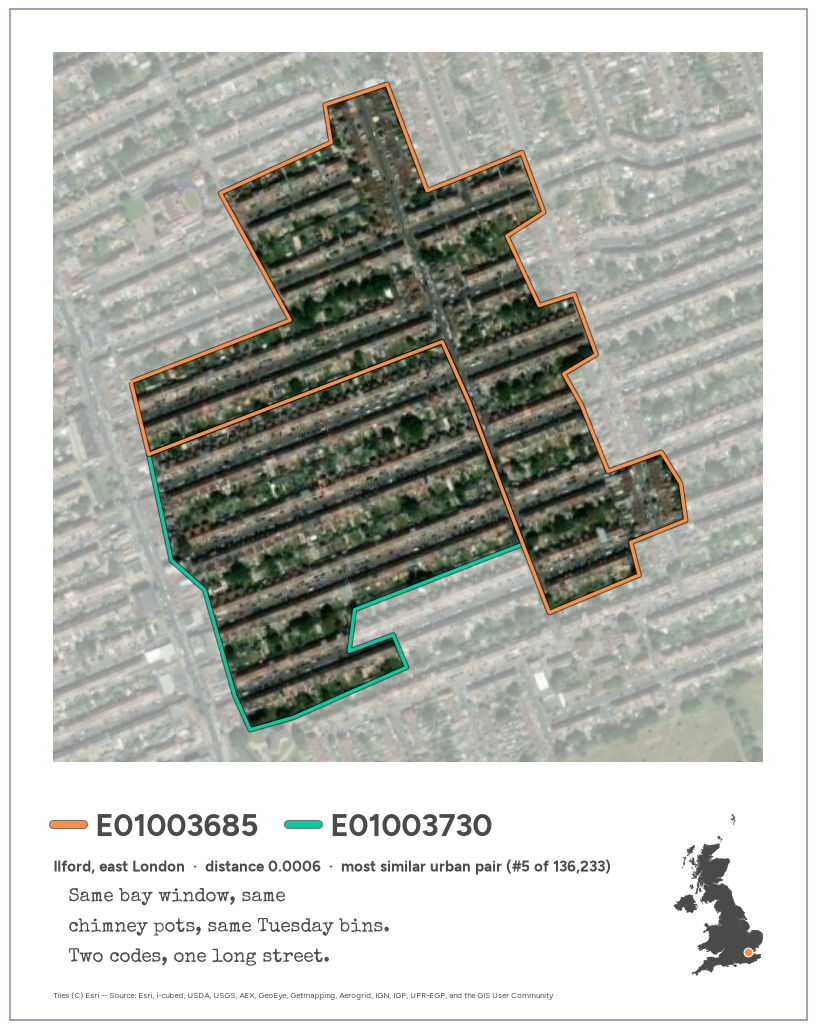

CPU times: user 3.56 s, sys: 211 ms, total: 3.78 s
Wall time: 4.29 s


In [6]:
%%time
uk_outline = tools.uk_outline(areas)
out_dir = tools.FIG_DIR / "submission"
for i, (kind, r) in enumerate(picks.iterrows(), 1):
    cap = CAPTIONS[kind]
    d = f"{r.dist:.3f}" if r.dist >= 0.01 else f"{r.dist:.4f}"
    subtitle = f"{cap['place']}  ·  distance {d}  ·  {cap['rank'](r)}"
    fig = tools.pair_card(areas, r.a, r.b, subtitle, uk_outline, haiku=cap["haiku"])
    print(tools.export_card(fig, f"{i}_{kind}", fig_dir=out_dir).relative_to(tools.ROOT))
    plt.show()

## Post text

The text for the LinkedIn post that goes with the three cards. It's kept in a plain-text block so the hashtags don't render as headings and it can be copied as is.

```text
#30DayMapChallenge, day 10: prompting only.

Every small area in the UK (46,832 of them) has a 2024 AlphaEarth embedding, made available through Imago: 64 numbers that sum up a year of satellite observations. Compare each area with the ones it touches and you get 136,233 pairs of neighbours, ranked from most different to most alike.

Three of them:

1. The most different: Staines Reservoirs and the streets of Stanwell next door.
2. The most alike: two stretches of farmland in County Armagh.
3. The most alike in a city: two halves of the same terraced streets in Ilford.

The first is the one you'd guess. The other two are more interesting: the boundaries we use to count people often split places that, as far as the satellites can tell, are the same place.

Everything here (the data processing, the maps, even the haiku) came from prompting Claude Code. No code written by hand.

#30DayMapChallenge #GeographicDataScience
```